# 🧹 Tunisian Car Listings — Data Cleaning

This notebook cleans `unified_car_listings.csv` following a specific pipeline:

1. Load the data
2. Drop unneeded columns: `source`, `is_new`, `listing_url`, `is_price_outlier`, `is_mileage_outlier`
3. **Keep both New and Used cars** — new cars are kept because they'll be needed for a future
   "is this price fair" model; we just make sure they don't get mixed into the **used-car**
   outlier detection below, since new vs. used cars naturally have very different
   price/mileage distributions
4. Inspect duplicates
5. Remove duplicates
6. Handle missing values
7. Detect & remove outliers using the **IQR method** on `price_tnd` and `mileage_km` —
   computed from **Used cars only** and applied **only to Used cars**, with boxplots
   **before and after** so the effect is visible. New cars pass through untouched.
8. Recombine Used + New and export the final cleaned dataset


## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
# Columns used to identify near duplicates
near_dupe_cols = [
    'make',
    'model',
    'year',
    'price_tnd',
    'mileage_km',
    'region'
]

DATA_PATH = 'unified_car_listings.csv'
OUTPUT_PATH = 'unified_car_listings_clean.csv'


## 1. Load the data

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} rows x {df.shape[1]} columns")
df.head()


Loaded 12,359 rows x 20 columns


,listing_id,source,title_raw,make,model,year,price_tnd,mileage_km,fuel_type,transmission,body_type,region,seller_type,listing_date,source_deal_label,condition,is_new,listing_url,is_price_outlier,is_mileage_outlier
0,automoto_tn_0,automoto_tn,Volkswagen Polo,Volkswagen,Polo,1996.0,12500.0,80000.0,Petrol,Manual,Unknown,Ben Arous,Private,2026-06-25,NaN,Used,False,https://automoto.tn/annonce-vehicule/id=d236ae...,False,False
1,automoto_tn_1,automoto_tn,Citroen Berlingo,Citroen,Berlingo,2025.0,26500.0,18000.0,Diesel,Manual,Unknown,Gafsa,Private,2026-06-23,NaN,Used,False,https://automoto.tn/annonce-vehicule/id=ec0a1c...,False,False
2,automoto_tn_2,automoto_tn,Peugeot 307,Peugeot,307,2005.0,30000.0,299000.0,Petrol,Manual,Unknown,Gabès,Private,2026-06-24,NaN,Used,False,https://automoto.tn/annonce-vehicule/id=c26324...,False,False
3,automoto_tn_3,automoto_tn,Volkswagen Jetta,Volkswagen,Jetta,2009.0,27000.0,379000.0,Petrol,Manual,Unknown,Ariana,Private,2026-06-23,NaN,Used,False,https://automoto.tn/annonce-vehicule/id=057181...,False,False
4,automoto_tn_4,automoto_tn,Peugeot 308,Peugeot,308,2015.0,26500.0,290000.0,Petrol,Manual,Unknown,Ariana,Private,2026-04-27,NaN,Used,False,https://automoto.tn/annonce-vehicule/id=aac80b...,False,False


## 2. Drop unneeded columns

- `source` — which website the listing came from, not needed for the analysis
- `is_new` — redundant with `condition` (perfectly correlated: `condition == 'New'` <=> `is_new == True`)
- `listing_url` — only useful for tracing back to the original ad, not for analysis
- `is_price_outlier`, `is_mileage_outlier` — we'll compute our **own** outlier detection with IQR below, so the pre-computed flags aren't needed


In [3]:
cols_to_drop = ['source', 'is_new', 'listing_url', 'is_price_outlier', 'is_mileage_outlier']
df = df.drop(columns=cols_to_drop)

print(f"Dropped columns: {cols_to_drop}")
print(f"Remaining columns ({df.shape[1]}): {df.columns.tolist()}")


Dropped columns: ['source', 'is_new', 'listing_url', 'is_price_outlier', 'is_mileage_outlier']
Remaining columns (15): ['listing_id', 'title_raw', 'make', 'model', 'year', 'price_tnd', 'mileage_km', 'fuel_type', 'transmission', 'body_type', 'region', 'seller_type', 'listing_date', 'source_deal_label', 'condition']


## 3. Keep both New and Used cars

We don't drop new cars — they're needed for a future model that checks whether a *new* car's
price is fair. We just note the split here; the outlier-removal step later on will be applied
to Used cars only, so new cars (which are naturally 0 km / higher price) don't get flagged as
"outliers" by a rule that doesn't apply to them.


In [4]:
print(df['condition'].value_counts())
print(f"\nTotal rows kept (both New and Used): {len(df):,}")

condition
Used    11339
New      1020
Name: count, dtype: int64

Total rows kept (both New and Used): 12,359


## 4. Inspect duplicates

We check duplicates at two levels before removing anything:
1. **Fully identical rows**
2. **Duplicate `listing_id`** (should be a unique key)

*(Note: `listing_url` was already dropped, so URL-level duplicate checking is no longer
possible — that's expected since we removed the column in step 2.)*


In [5]:
n_exact_dupes = df.duplicated().sum()
n_id_dupes = df.duplicated(subset=['listing_id']).sum()

print(f"Fully identical duplicate rows : {n_exact_dupes:,}")
print(f"Duplicate listing_id           : {n_id_dupes:,}")


Fully identical duplicate rows : 0
Duplicate listing_id           : 0


In [6]:
# Look at the actual duplicate rows (if any) before deciding to remove them
dupes_preview = df[df.duplicated(keep=False)].sort_values(by=df.columns.tolist())
print(f"Preview of duplicate rows ({len(dupes_preview)} total):")
dupes_preview.head(10)


Preview of duplicate rows (0 total):


,listing_id,title_raw,make,model,year,price_tnd,mileage_km,fuel_type,transmission,body_type,region,seller_type,listing_date,source_deal_label,condition


## 5. Remove duplicates

In [7]:
# Inspect near-duplicates: likely the same car cross-listed on multiple platforms
near_dupes = df[df.duplicated(subset=near_dupe_cols, keep=False)].sort_values(near_dupe_cols)
near_dupes[[ 'make', 'model', 'year', 'price_tnd', 'mileage_km', 'region','condition']].head(10)

,make,model,year,price_tnd,mileage_km,region,condition
1278,Audi,A3,NaN,33000.0,304000.0,Unknown,Used
1298,Audi,A3,NaN,33000.0,304000.0,Unknown,Used
399,Audi,A3 Berline,NaN,149990.0,0.0,Unknown,New
543,Audi,A3 Berline,NaN,149990.0,0.0,Unknown,New
378,Audi,A3 Sportback,NaN,129990.0,0.0,Unknown,New
541,Audi,A3 Sportback,NaN,129990.0,0.0,Unknown,New
64,Audi,A4,2002.0,24000.0,120000.0,Nabeul,Used
65,Audi,A4,2002.0,24000.0,120000.0,Nabeul,Used
451,Audi,A5,NaN,219990.0,0.0,Unknown,New
545,Audi,A5,NaN,219990.0,0.0,Unknown,New


In [8]:
# Count rows before
rows_before = len(df)

# Drop near duplicates (keep first occurrence)
df = df.drop_duplicates(subset=near_dupe_cols, keep='first').reset_index(drop=True)

# Count rows after
rows_after = len(df)

print(f"Rows before: {rows_before:,}")
print(f"Rows after : {rows_after:,}")
print(f"Removed    : {rows_before - rows_after:,} near-duplicate rows")

# Verify no near duplicates remain
assert df.duplicated(subset=near_dupe_cols).sum() == 0

print("\nConfirmed: no near-duplicates remain.")

Rows before: 12,359
Rows after : 11,959
Removed    : 400 near-duplicate rows

Confirmed: no near-duplicates remain.


## 6. Missing values

Let's see what's missing, then handle each column sensibly. This applies to the full dataset
(New + Used together):

| Column | Strategy |
|---|---|
| `year` | Impute with the median year for the same `make` + `model`; fallback to the overall median |
| `price_tnd` | Drop rows with missing price — price is central to this analysis and can't be reliably guessed |
| `mileage_km` | Drop rows with missing mileage — same reasoning |
| `listing_date` | Leave missing (not critical, no reliable way to impute a date) |
| `source_deal_label` | Fill with `"Not rated"` — missing simply means the source didn't provide a rating |


In [9]:
missing = df.isna().sum()
missing[missing > 0].sort_values(ascending=False)


source_deal_label    3400
listing_date         1938
year                 1911
price_tnd             491
mileage_km            210
dtype: int64

In [10]:
# --- define used and new cars ---
df_used = df[df['condition'] == 'Used'].copy()
df_new = df[df['condition'] == 'New'].copy()

# --- used cars year: impute with median year within same make+model, fallback to global median ---
n_year_missing = df_used['year'].isna().sum()
df_used['year'] = df_used['year'].fillna(df_used.groupby(['make', 'model'])['year'].transform('median'))
df_used['year'] = df_used['year'].fillna(df_used['year'].median())
print(f"Imputed {n_year_missing:,} missing 'year' values (median year of same make+model)")
# --- new cars year: fill value with 2026 ---
n_year_missing_new = df_new['year'].isna().sum()
df_new['year'] = df_new['year'].fillna(2026)
print(f"Filled {n_year_missing_new:,} missing 'year' values for new cars with 2026")

df = pd.concat([df_used, df_new], ignore_index=True)


# Check remaining missing years
remaining_missing = df['year'].isna().sum()

print(f"\nRemaining missing year values: {remaining_missing:,}")

Imputed 1,137 missing 'year' values (median year of same make+model)
Filled 774 missing 'year' values for new cars with 2026

Remaining missing year values: 0


In [11]:
# --- source_deal_label: missing = source didn't rate the listing ---
n_label_missing = df['source_deal_label'].isna().sum()
df['source_deal_label'] = df['source_deal_label'].fillna('Not rated')
print(f"Filled {n_label_missing:,} missing 'source_deal_label' values with 'Not rated'")


Filled 3,400 missing 'source_deal_label' values with 'Not rated'


In [12]:
# --- Fill missing mileage for 2026 cars with 0 ---
mask = (df['year'] == 2026) & (df['mileage_km'].isna())
df.loc[mask, 'mileage_km'] = 0

print(f"Filled {mask.sum():,} missing mileage values with 0 for 2026 cars.")

# --- price_tnd & mileage_km: drop remaining rows where these are missing ---
rows_before = len(df)
df = df.dropna(subset=['price_tnd', 'mileage_km']).reset_index(drop=True)
rows_after = len(df)

print(f"Dropped {rows_before - rows_after:,} rows with missing price_tnd or mileage_km")
print(f"Rows remaining: {rows_after:,}")

Filled 12 missing mileage values with 0 for 2026 cars.
Dropped 634 rows with missing price_tnd or mileage_km
Rows remaining: 11,325


In [13]:
# --- listing_date: leave as-is (not imputed) ---
print(f"'listing_date' still has {df['listing_date'].isna().sum():,} missing values - left untouched")
print()
print("Missing values remaining per column:")
df.isna().sum()
df.info()

'listing_date' still has 1,823 missing values - left untouched

Missing values remaining per column:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11325 entries, 0 to 11324
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   listing_id         11325 non-null  object 
 1   title_raw          11325 non-null  object 
 2   make               11325 non-null  object 
 3   model              11325 non-null  object 
 4   year               11325 non-null  float64
 5   price_tnd          11325 non-null  float64
 6   mileage_km         11325 non-null  float64
 7   fuel_type          11325 non-null  object 
 8   transmission       11325 non-null  object 
 9   body_type          11325 non-null  object 
 10  region             11325 non-null  object 
 11  seller_type        11325 non-null  object 
 12  listing_date       9502 non-null   object 
 13  source_deal_label  11325 non-null  object 
 14  condition        

## 7. Outlier detection & removal (IQR method) — Used cars only

New cars have a fundamentally different price/mileage profile (mostly ~0 km, and priced at
full retail), so applying the same IQR bounds to them would incorrectly flag legitimate new
cars as "outliers". Instead, we:

1. Split the data into `df_used` and `df_new`
2. Compute IQR bounds **from `df_used` only**:
   ```
   IQR = Q3 - Q1
   lower bound = Q1 - 1.5 x IQR
   upper bound = Q3 + 1.5 x IQR
   ```
3. Remove outlier rows **only from `df_used`** — `df_new` passes through untouched
4. Recombine `df_used` (cleaned) + `df_new` (untouched) into the final dataset

Boxplots are shown **before and after**, on the Used subset, so the effect is clearly visible.


Used cars: 10,564 rows
New cars : 761 rows (set aside, untouched by outlier removal)


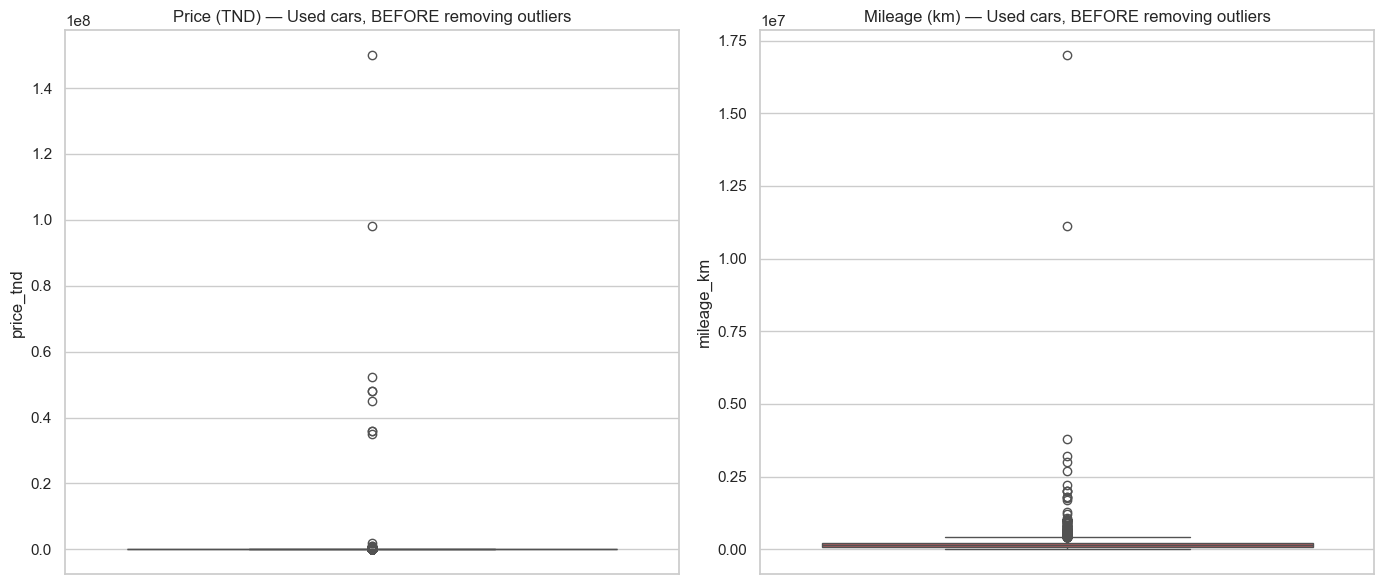

price_tnd    limits: [1,400, 800,000] TND
mileage_km   limits: [1,000, 600,000] km

Rows flagged as price outliers   : 77
Rows flagged as mileage outliers  : 294
Rows flagged as outlier (either)  : 350
Price outliers (sorted by price):


,listing_id,make,model,year,price_tnd,mileage_km
7797,baniola_tn_2096,Hyundai,Tucson 2022 4000 Km,2022.0,1.0,40000.0
7944,baniola_tn_2259,Citroen,C4 Full Options - Importée de France,2011.0,1.0,380000.0
262,zmorda_tn_73,Renault,Clio,2017.0,1.0,300000.0
502,zmorda_tn_318,Haval,H9,2017.0,1.0,59000.0
6052,baniola_tn_67,Peugeot,Expert 2021 Diesel,2021.0,1.0,125000.0
...,...,...,...,...,...,...
825,zmorda_tn_674,Citroen,C4 Cactus,2016.0,48000000.0,71524.0
7828,baniola_tn_2128,DongFeng,Sx3 2022 65000 Km,2022.0,48000000.0,56000.0
5736,automax_tn_135,SEAT,Leon,2016.0,52149505.0,80000.0
8314,baniola_tn_2695,Volkswagen,Golf 2010 328 Km,2010.0,98225724.0,328.0



Mileage outliers (sorted by mileage):


,listing_id,make,model,year,price_tnd,mileage_km
9069,automobile_tn_149,Volkswagen,ID.4 Prime,2025.0,125000.0,0.0
9932,automobile_tn_1028,Toyota,Land Cruiser 300 GXR,2025.0,529000.0,0.0
32,automoto_tn_32,Renault,Scenic,2004.0,18000.0,0.0
52,automoto_tn_53,Fiat,Fiorino,2019.0,26000.0,0.0
8302,baniola_tn_2677,Peugeot,106 1995 1 Km,1995.0,12000.0,1.0
...,...,...,...,...,...,...
8255,baniola_tn_2619,Renault,Laguna 2004 3000 Km,2004.0,16000.0,3000000.0
91,automoto_tn_94,Dacia,Sandero,2009.0,170000.0,3200000.0
7241,baniola_tn_1458,Mercedes-Benz,Classe C 2008 38000 Km,2008.0,35000.0,3800000.0
2990,scoutcar_tn_52022,Lancia,Ypsilon,2016.0,28000.0,11111111.0


In [14]:
# --- define used and new cars ---
df_used = df[df['condition'] == 'Used'].copy()
df_new = df[df['condition'] == 'New'].copy()
print(f"Used cars: {len(df_used):,} rows")
print(f"New cars : {len(df_new):,} rows (set aside, untouched by outlier removal)")

# --- BEFORE: boxplots on the raw scale (Used cars only) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(y=df_used['price_tnd'], ax=axes[0], color='#C44E52')
axes[0].set_title('Price (TND) — Used cars, BEFORE removing outliers')
axes[0].set_ylabel('price_tnd')

sns.boxplot(y=df_used['mileage_km'], ax=axes[1], color='#C44E52')
axes[1].set_title('Mileage (km) — Used cars, BEFORE removing outliers')
axes[1].set_ylabel('mileage_km')

plt.tight_layout()
plt.show()

# --- define fixed domain limits ---
PRICE_MIN, PRICE_MAX = 1_400, 800_000       # TND
MILEAGE_MIN, MILEAGE_MAX = 1_000, 600_000   # km
MILEAGE_2026_MIN, MILEAGE_2026_MAX = 0, 19_000

print(f"price_tnd    limits: [{PRICE_MIN:,}, {PRICE_MAX:,}] TND")
print(f"mileage_km   limits: [{MILEAGE_MIN:,}, {MILEAGE_MAX:,}] km")

is_price_outlier = ~df_used['price_tnd'].between(PRICE_MIN, PRICE_MAX)
is_2026 = df_used['year'] == 2026

is_mileage_outlier = (
    (~is_2026 & ~df_used['mileage_km'].between(MILEAGE_MIN, MILEAGE_MAX)) |
    (is_2026 & ~df_used['mileage_km'].between(MILEAGE_2026_MIN, MILEAGE_2026_MAX))
)
is_outlier = is_price_outlier | is_mileage_outlier

print(f"\nRows flagged as price outliers   : {is_price_outlier.sum():,}")
print(f"Rows flagged as mileage outliers  : {is_mileage_outlier.sum():,}")
print(f"Rows flagged as outlier (either)  : {is_outlier.sum():,}")

# --- view the flagged outliers as tables ---
print("Price outliers (sorted by price):")
price_outliers_table = df_used.loc[is_price_outlier, ['listing_id', 'make', 'model', 'year',
                                                        'price_tnd', 'mileage_km']].sort_values('price_tnd')
display(price_outliers_table)

print(f"\nMileage outliers (sorted by mileage):")
mileage_outliers_table = df_used.loc[is_mileage_outlier, ['listing_id', 'make', 'model', 'year',
                                                            'price_tnd', 'mileage_km']].sort_values('mileage_km')
display(mileage_outliers_table)

In [15]:
# --- snapshot BEFORE removal, for the side-by-side comparison ---
before_outliers = df_used[['price_tnd', 'mileage_km']].copy()

rows_before = len(df_used)
df_used = df_used[~is_outlier].reset_index(drop=True)
rows_after = len(df_used)

print(f"\nUsed-car rows before removing outliers: {rows_before:,}")
print(f"Used-car rows after removing outliers : {rows_after:,}")
print(f"Removed                               : {rows_before - rows_after:,} rows "
      f"({(rows_before - rows_after) / rows_before * 100:.1f}%)")


Used-car rows before removing outliers: 10,564
Used-car rows after removing outliers : 10,214
Removed                               : 350 rows (3.3%)


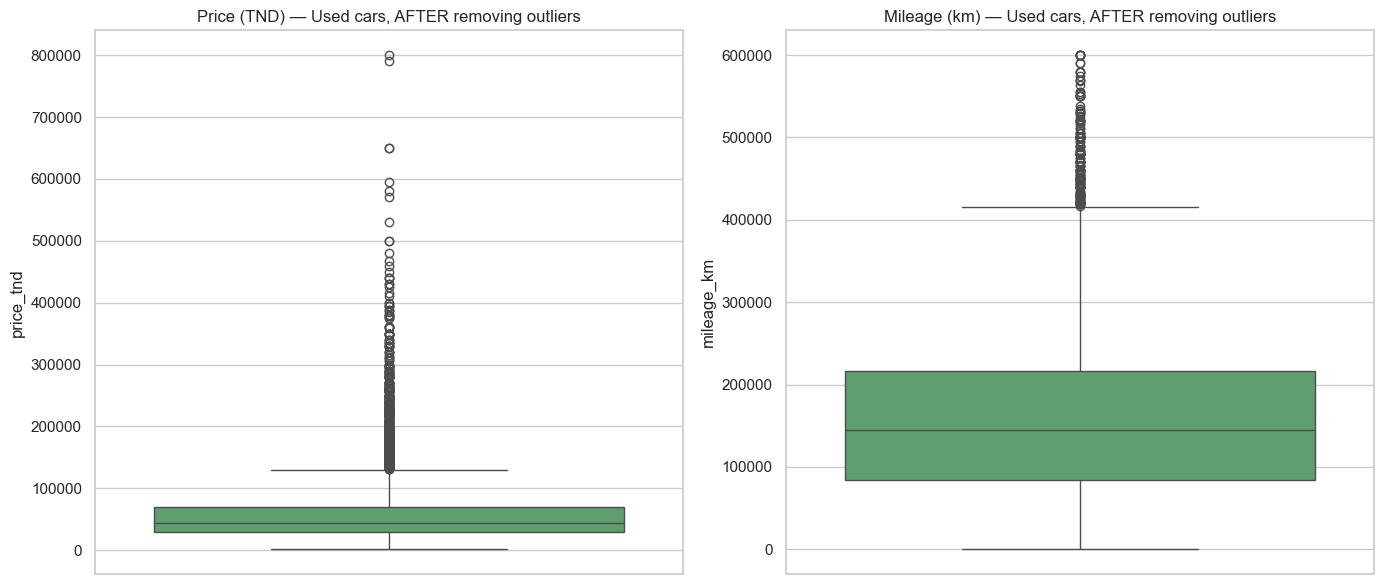

In [16]:
# --- AFTER: boxplots on the raw scale (Used cars only) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(y=df_used['price_tnd'], ax=axes[0], color='#55A868')
axes[0].set_title('Price (TND) — Used cars, AFTER removing outliers')
axes[0].set_ylabel('price_tnd')

sns.boxplot(y=df_used['mileage_km'], ax=axes[1], color='#55A868')
axes[1].set_title('Mileage (km) — Used cars, AFTER removing outliers')
axes[1].set_ylabel('mileage_km')

plt.tight_layout()
plt.show()


### Side-by-side comparison (BEFORE vs. AFTER, Used cars only)

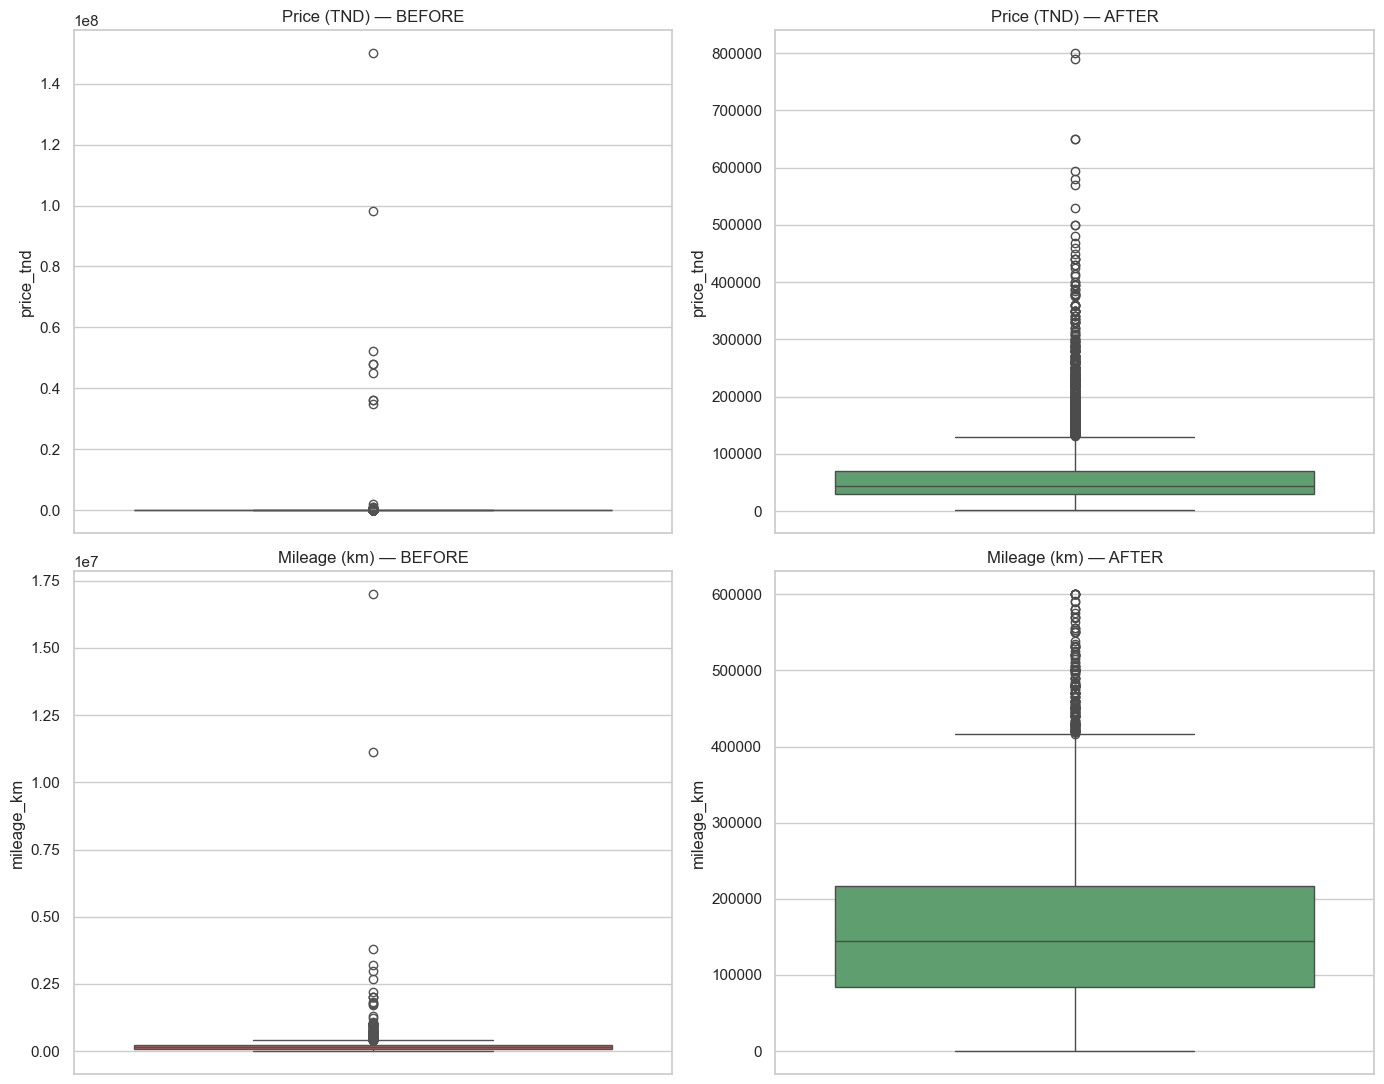

In [17]:
# --- side-by-side comparison (BEFORE vs. AFTER, Used cars only) ---
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

sns.boxplot(y=before_outliers['price_tnd'], ax=axes[0, 0], color='#C44E52')
axes[0, 0].set_title('Price (TND) — BEFORE')

sns.boxplot(y=df_used['price_tnd'], ax=axes[0, 1], color='#55A868')
axes[0, 1].set_title('Price (TND) — AFTER')

sns.boxplot(y=before_outliers['mileage_km'], ax=axes[1, 0], color='#C44E52')
axes[1, 0].set_title('Mileage (km) — BEFORE')

sns.boxplot(y=df_used['mileage_km'], ax=axes[1, 1], color='#55A868')
axes[1, 1].set_title('Mileage (km) — AFTER')

plt.tight_layout()
plt.show()

In [18]:
# --- recombine cleaned Used cars + untouched New cars ---
df = pd.concat([df_used, df_new], ignore_index=True)

print(f"Final combined dataset: {len(df):,} rows "
      f"({len(df_used):,} cleaned Used + {len(df_new):,} untouched New)")
df['condition'].value_counts()

Final combined dataset: 10,975 rows (10,214 cleaned Used + 761 untouched New)


condition
Used    10214
New       761
Name: count, dtype: int64

In [19]:
import re

FUEL_WORDS = ['essence', 'diesel', 'hybride', 'electrique', 'électrique', 'gpl', 'hybrid', 'electric']

FILLER_PHRASES = [
    r'à\s*vendre', r'a\s*vendre', r'avendre',
    r'en\s+excellente?\s+[ée]tat', r'exelente\s+etat', r'excellente?\s+etat',
    r'premi[eè]re\s+main', r'1[eè]?re\s+main',
    r'toutes?\s+options', r'full\s+options',
    r'import[ée]e?(\s+de\s+\w+)?', r'immatricul[ée]e?\s+au\s+\w+',
    r'mod[eè]le\s+unique', r'[ée]tat\s+t\.?\s*t\.?\s*neuf',
    r'rare\s+etat', r'impeccable', r'faible\s+km',
    r'magnifique', r'propre', r'mod[eè]le', r'\bmodel\b',
    r'boite\s+auto(matique)?', r'boite\s+manuelle',
    r'occasion', r'neuf(ve)?',
]

def clean_model(model_text, region):
    if pd.isna(model_text):
        return model_text
    text = str(model_text)

    # Remove emoji / pictographs / misc symbols
    text = re.sub(r'[\U0001F000-\U0001FFFF\u2600-\u27BF]', ' ', text)

    # Remove mileage pattern: number (space/dot/comma-separated OR contiguous) + Km
    text = re.sub(r'\b(?:\d{1,3}(?:[\s.,]\s?\d{3})+|\d{2,7})\s*km\b', ' ', text, flags=re.IGNORECASE)

    # Remove standalone year tokens (1950-2049)
    text = re.sub(r'\b(19[5-9]\d|20[0-4]\d)\b', ' ', text)

    # Remove the row's region name if it leaked into the model text
    if pd.notna(region) and str(region).strip():
        text = re.sub(r'\b' + re.escape(str(region)) + r'\b', ' ', text, flags=re.IGNORECASE)

    # Remove fuel type words
    for fw in FUEL_WORDS:
        text = re.sub(r'\b' + fw + r'\b', ' ', text, flags=re.IGNORECASE)

    # Remove marketing filler phrases
    for phrase in FILLER_PHRASES:
        text = re.sub(phrase, ' ', text, flags=re.IGNORECASE)

    # Remove leftover stray punctuation (asterisks, pipes, bullets, dashes)
    text = re.sub(r'[\*\|•–—]', ' ', text)
    text = re.sub(r'\s*-\s*-+\s*', ' ', text)
    text = re.sub(r'^\s*-\s*', '', text)
    text = re.sub(r'\s*-\s*$', '', text)

    # Collapse whitespace & strip stray punctuation at the ends
    text = re.sub(r'\s+', ' ', text).strip(' .,-–—')

    return text if text else model_text  # fallback to original if we stripped everything


def recover_trim_number(model_clean, title_raw):
    """The source website sometimes only stores 'Golf' (no trim number) in the model
    field, even though the trim (e.g. '6', '7', '8', '7.5') is right there in title_raw.
    This pulls it back in when model_clean doesn't already end in a number."""
    if pd.isna(model_clean) or pd.isna(title_raw):
        return model_clean
    if re.search(r'\d$', model_clean):
        return model_clean  # already has a trailing number, nothing to recover
    pattern = re.escape(model_clean) + r'\s+(\d{1,2}(?:\.\d)?)\b'
    m = re.search(pattern, str(title_raw), flags=re.IGNORECASE)
    if m:
        return f'{model_clean} {m.group(1)}'
    return model_clean


df['model_clean'] = df.apply(lambda r: clean_model(r['model'], r['region']), axis=1)
df['model_clean'] = df.apply(lambda r: recover_trim_number(r['model_clean'], r['title_raw']), axis=1)

n_changed = (df['model'] != df['model_clean']).sum()
print(f"Cleaned {n_changed:,} / {len(df):,} model values ({n_changed/len(df)*100:.1f}%)")

Cleaned 3,179 / 10,975 model values (29.0%)


In [20]:
# Preview a sample of before -> after
sample = df[df['model'] != df['model_clean']].sample(15, random_state=1)
sample[['title_raw', 'model', 'model_clean']]


,title_raw,model,model_clean
6952,Hyundai I20 1. 0 Grdi Essence Hybrid Léger,I20 1. 0 Grdi Essence Hybrid Léger,I20 1. 0 Grdi Léger
6622,Hyundai I10 2022 Essence,I10 2022 Essence,I10
5889,Ford Fiesta Titanium 2015,Fiesta Titanium 2015,Fiesta Titanium
8436,Volkswagen Polo Essence 300 000 Km,Polo Essence 300 000 Km,Polo
7217,Nissan Navara 2007 4000 Km,Navara 2007 4000 Km,Navara
6575,Ford Ka 2015 Essence,Ka 2015 Essence,Ka
7181,Škoda Kamiq 2021,Kamiq 2021,Kamiq
6507,Ssangyong Tivoli 2021 Essence,Tivoli 2021 Essence,Tivoli
6309,Renault Megane 2004 Essence,Megane 2004 Essence,Megane
7558,Ssangyong Tivoli 2017 372000 Km,Tivoli 2017 372000 Km,Tivoli


In [21]:
# Replace 'model' with the cleaned version (keep original title_raw for full traceability)
df['model'] = df['model_clean']
df = df.drop(columns=['model_clean'])
print("'model' column replaced with the cleaned version.")


'model' column replaced with the cleaned version.


## 9. Final check & export

Final dataset = cleaned Used cars + untouched New cars, recombined.


In [22]:
print("Final dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print()
print("Missing values remaining:")
print(df.isna().sum())
print()
print("Duplicate rows remaining:", df.duplicated().sum())
df.describe()


Final dataset shape: (10975, 15)
Columns: ['listing_id', 'title_raw', 'make', 'model', 'year', 'price_tnd', 'mileage_km', 'fuel_type', 'transmission', 'body_type', 'region', 'seller_type', 'listing_date', 'source_deal_label', 'condition']

Missing values remaining:
listing_id              0
title_raw               0
make                    0
model                   0
year                    0
price_tnd               0
mileage_km              0
fuel_type               0
transmission            0
body_type               0
region                  0
seller_type             0
listing_date         1779
source_deal_label       0
condition               0
dtype: int64

Duplicate rows remaining: 0


,year,price_tnd,mileage_km
count,10975.000000,10975.000000,10975.000000
mean,2016.588383,66426.102415,148783.975945
std,6.766554,63551.169904,106246.485893
min,1972.000000,1500.000000,0.000000
25%,2013.000000,31500.000000,70000.000000
50%,2018.000000,46500.000000,135000.000000
75%,2021.000000,77000.000000,210000.000000
max,2026.000000,845000.000000,600000.000000


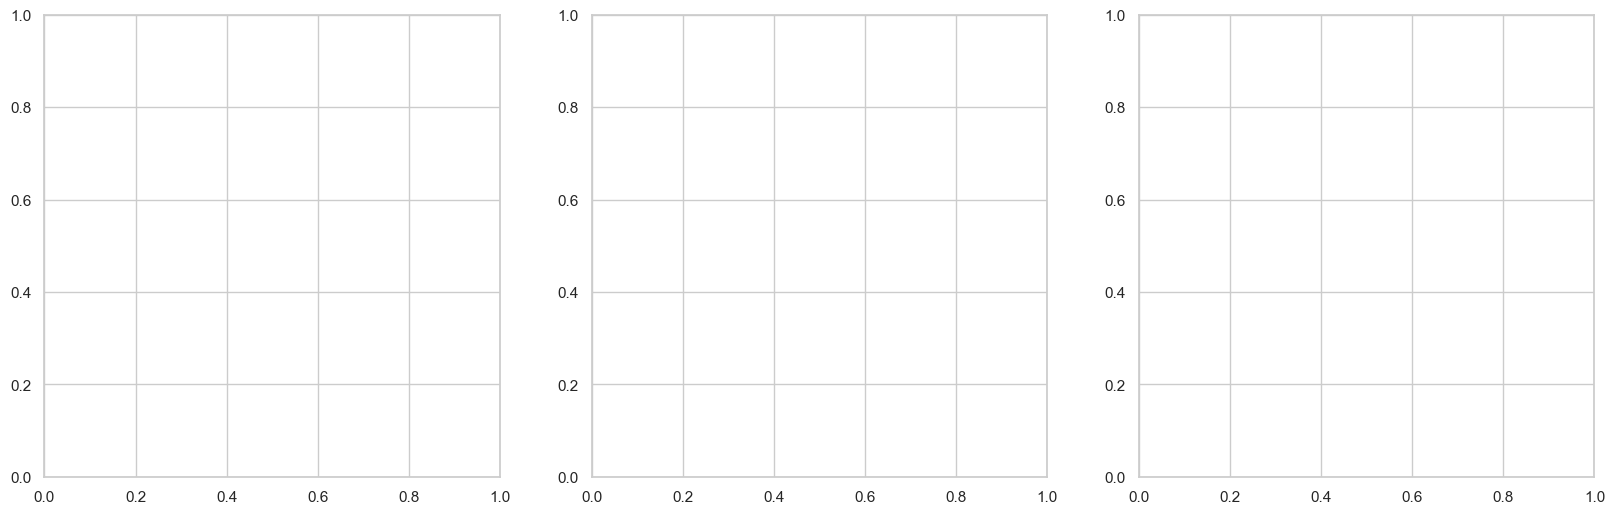

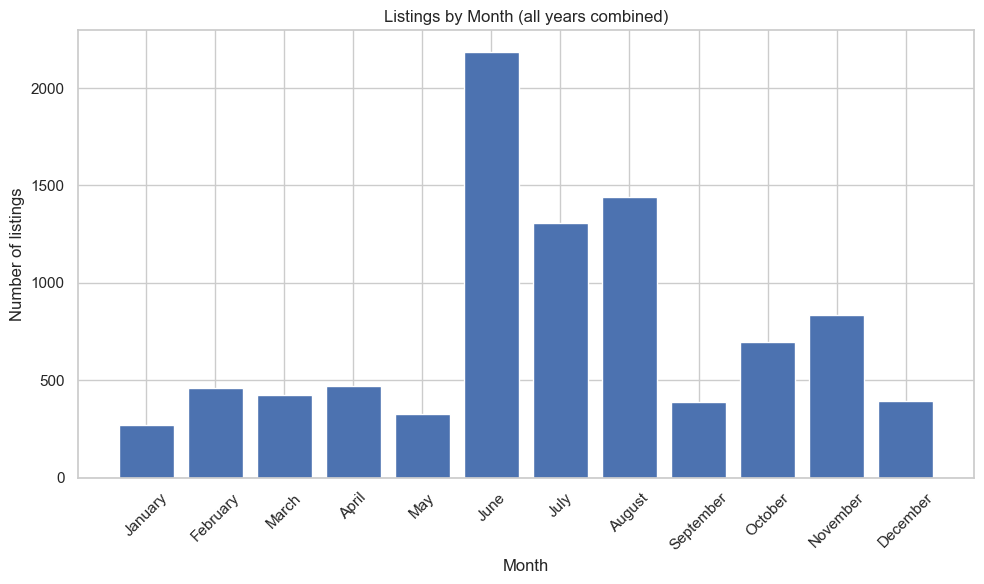

<Figure size 1000x600 with 0 Axes>

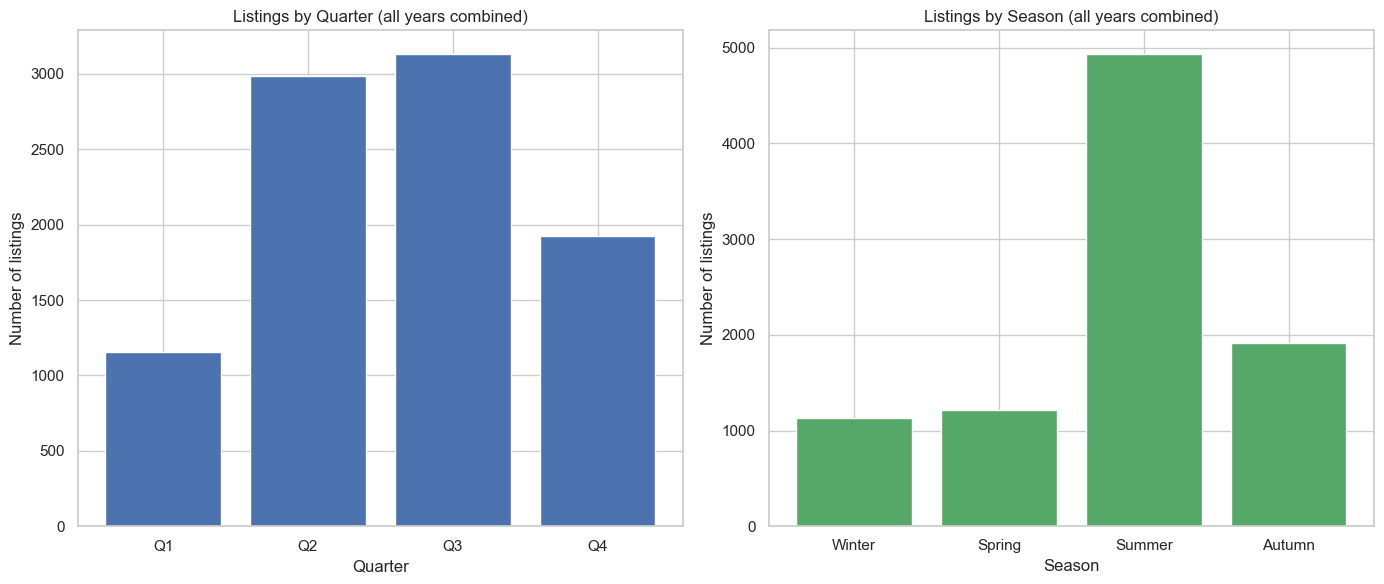

In [23]:
df['listing_date'] = pd.to_datetime(df['listing_date'], errors='coerce')

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
by_month = df['listing_date'].dt.month_name().value_counts().reindex(month_order)

plt.figure(figsize=(10, 6))
plt.bar(by_month.index, by_month.values, color='#4C72B0')
plt.title('Listings by Month (all years combined)')
plt.xlabel('Month')
plt.ylabel('Number of listings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- Listings by day of week (bar chart) ---
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow = df['listing_date'].dt.day_name().value_counts().reindex(dow_order)
axes[1].bar(dow.index, dow.values, color='#55A868')
axes[1].set_title('Listings by Day of Week')
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Number of listings')
axes[1].tick_params(axis='x', rotation=45)

# --- Listings by year (bar chart) ---
yearly = df['listing_date'].dt.year.value_counts().sort_index()
axes[2].bar(yearly.index.astype(int).astype(str), yearly.values, color='#C44E52')
axes[2].set_title('Listings by Year')
axes[2].set_xlabel('Year')
axes[2].set_ylabel('Number of listings')

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- By quarter ---
quarter_labels = {1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4'}
by_quarter = df['listing_date'].dt.quarter.map(quarter_labels).value_counts().reindex(['Q1', 'Q2', 'Q3', 'Q4'])
axes[0].bar(by_quarter.index, by_quarter.values, color='#4C72B0')
axes[0].set_title('Listings by Quarter (all years combined)')
axes[0].set_xlabel('Quarter')
axes[0].set_ylabel('Number of listings')

# --- By season (Winter=Dec-Feb, Spring=Mar-May, Summer=Jun-Aug, Autumn=Sep-Nov) ---
month_to_season = {12: 'Winter', 1: 'Winter', 2: 'Winter',
                    3: 'Spring', 4: 'Spring', 5: 'Spring',
                    6: 'Summer', 7: 'Summer', 8: 'Summer',
                    9: 'Autumn', 10: 'Autumn', 11: 'Autumn'}
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
by_season = df['listing_date'].dt.month.map(month_to_season).value_counts().reindex(season_order)
axes[1].bar(by_season.index, by_season.values, color='#55A868')
axes[1].set_title('Listings by Season (all years combined)')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('Number of listings')

plt.tight_layout()
plt.show()

In [24]:
df.to_csv(OUTPUT_PATH, index=False)
print(f"Saved cleaned dataset to '{OUTPUT_PATH}'  ({len(df):,} rows x {df.shape[1]} columns)")


Saved cleaned dataset to 'unified_car_listings_clean.csv'  (10,975 rows x 15 columns)


## 10. Save the cleaned data to PostgreSQL

Loads the final cleaned dataframe into a `car_listings` table in your `AutoSouk_DS` database.

- Update `DB_HOST`/`DB_PORT` if your Postgres isn't running on the default local port.
- `if_exists='replace'` drops and recreates the table each run — change to `'append'` if you
  want to add new listings to an existing table instead of overwriting it.
- Explicit column types are set (integers for `year`/`mileage_km`, rather than letting pandas
  default everything numeric to `double precision`), plus a primary key on `listing_id` and
  indexes on `(make, model)` and `condition` for faster filtering/joins later.


In [25]:
from sqlalchemy import create_engine, text, Integer, Float, Text, DateTime

DB_HOST = 'localhost'
DB_PORT = 5432
DB_NAME = 'AutoSouk_DB'
DB_USER = 'postgres'
DB_PASSWORD = '12345678'
TABLE_NAME = 'used_cars_tn'

engine = create_engine(f'postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}')

# quick connectivity check
with engine.connect() as conn:
    version = conn.execute(text('SELECT version();')).fetchone()[0]
    print(f"Connected OK -> {version}")


Connected OK -> PostgreSQL 16.11, compiled by Visual C++ build 1944, 64-bit


In [26]:
# --- prep dtypes for a clean Postgres schema ---
df_pg = df.copy()
df_pg['listing_date'] = pd.to_datetime(df_pg['listing_date'], errors='coerce')
df_pg['year'] = df_pg['year'].round().astype('Int64')          # guard against any .5 values from median imputation
df_pg['mileage_km'] = df_pg['mileage_km'].astype('Int64')

dtype_map = {
    'listing_id': Text,
    'title_raw': Text,
    'make': Text,
    'model': Text,
    'year': Integer,
    'price_tnd': Float,
    'mileage_km': Integer,
    'fuel_type': Text,
    'transmission': Text,
    'body_type': Text,
    'region': Text,
    'seller_type': Text,
    'listing_date': DateTime,
    'source_deal_label': Text,
    'condition': Text,
}

df_pg.to_sql(TABLE_NAME, engine, if_exists='replace', index=False, dtype=dtype_map, chunksize=1000)
print(f"Loaded {len(df_pg):,} rows into '{TABLE_NAME}'")


Loaded 10,975 rows into 'used_cars_tn'


In [27]:
# --- add a primary key + helpful indexes (run once per fresh table load) ---
with engine.begin() as conn:
    conn.execute(text(f'ALTER TABLE {TABLE_NAME} ADD PRIMARY KEY (listing_id);'))
    conn.execute(text(f'CREATE INDEX IF NOT EXISTS idx_make_model ON {TABLE_NAME} (make, model);'))
    conn.execute(text(f'CREATE INDEX IF NOT EXISTS idx_condition ON {TABLE_NAME} (condition);'))

print("Added primary key on listing_id, indexes on (make, model) and condition.")


Added primary key on listing_id, indexes on (make, model) and condition.


In [28]:
# --- verify the load ---
with engine.connect() as conn:
    count = conn.execute(text(f'SELECT COUNT(*) FROM {TABLE_NAME};')).scalar()
    print(f"Row count in Postgres table '{TABLE_NAME}': {count:,}  (expected {len(df_pg):,})")
    assert count == len(df_pg), "Row count mismatch - investigate before trusting the table!"

    preview = pd.read_sql(f'SELECT * FROM {TABLE_NAME} LIMIT 5;', conn)
preview


Row count in Postgres table 'used_cars_tn': 10,975  (expected 10,975)


,listing_id,title_raw,make,model,year,price_tnd,mileage_km,fuel_type,transmission,body_type,region,seller_type,listing_date,source_deal_label,condition
0,automoto_tn_0,Volkswagen Polo,Volkswagen,Polo,1996,12500.0,80000,Petrol,Manual,Unknown,Ben Arous,Private,2026-06-25,Not rated,Used
1,automoto_tn_1,Citroen Berlingo,Citroen,Berlingo,2025,26500.0,18000,Diesel,Manual,Unknown,Gafsa,Private,2026-06-23,Not rated,Used
2,automoto_tn_2,Peugeot 307,Peugeot,307,2005,30000.0,299000,Petrol,Manual,Unknown,Gabès,Private,2026-06-24,Not rated,Used
3,automoto_tn_3,Volkswagen Jetta,Volkswagen,Jetta,2009,27000.0,379000,Petrol,Manual,Unknown,Ariana,Private,2026-06-23,Not rated,Used
4,automoto_tn_4,Peugeot 308,Peugeot,308,2015,26500.0,290000,Petrol,Manual,Unknown,Ariana,Private,2026-04-27,Not rated,Used
